In [ ]:
!pip install gtts -q  # quiet install gtts

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import Audio, display, clear_output
from gtts import gTTS
from pydub import AudioSegment  # warning
from scipy.signal import resample, butter, lfilter

from google.colab import drive
drive.mount('/content/drive')

/usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


#Manipolazione di una traccia audio text-to-speech

Autore: Giulia Ponassi, Matricola: 6145273

## Introduzione

L'obiettivo principale del progetto é mostrare come una traccia audio text-to-speech venga modificata tramite algoritmi che alterano la voce, senza renderla incomprensibile.

Nella prima parte del notebook esploro come manipolazioni matematiche di un segnale audio possano trasformare una semplice frase di testo, generata in text-to-speech, e alterarne le caratteristiche fondamentali: tempo, frequenza, ampiezza.

Nella seconda parte del notebook ricreo effetti presenti nei videogiochi e/o nella vita di tutti i giorni.




In [ ]:
def tts_to_wav(text, filename="tts_output.wav"):
    tts = gTTS(text=text, lang="it")
    tts.save("temp.mp3")  # mp3 temporaneo

    sound = AudioSegment.from_mp3("temp.mp3")
    sound.export(filename, format="wav")
    # fonte: https://github.com/jiaaro/pydub

    return filename

In [ ]:
text = "Ciao a tutti, sono Giulia."
filename = "base_voice.wav"

tts_to_wav(text, filename)
y_base, sr_base = librosa.load(filename, sr=None)

Audio(y_base, rate=sr_base)

In [ ]:
def plot_analysis(y, sr, title="Analisi Audio"):
    plt.figure(figsize=(10, 8), layout='constrained')

    # ampiezza nel tempo
    plt.subplot(2, 1, 1)
    librosa.display.waveshow(y, sr=sr, alpha=0.8)
    plt.title("Ampiezza nel tempo")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Ampiezza")
    plt.ylim(-1.1, 1.1)

    # spettrogramma
    plt.subplot(2, 1, 2)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis='time', y_axis='log', cmap='magma')
    plt.colorbar(format="%+2.0f dB")
    plt.title("Spettrogramma")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout
    plt.show()

In questa parte di notebook, ho implementato tre effetti che manipolano il segnale nel dominio del tempo e della frequenza, permettendoci di osservare visivamente come queste modifiche alterino la struttura dell'onda sonora.

Ho creato un editor che permette di modificare i valori degli algoritmi tramite slider, ritornando grafici e l'audio modificato. Si trova alla fine della spiegazione di questi tre primi effetti.

## Velocità
Il primo effetto modifica la velocità, tramite una tecnica di ricampionamento (resampling). Dal punto di vista teorico, stiamo modificando il numero di campioni che compongono il segnale, ma manteniamo fissa la frequenza di campionamento.

L'audio digitale è una sequenza di numeri, campioni, riprodotti a una velocità fissa, chiamata sample rate.
Quando raddoppio la velocità, la funzione calcola una nuova lunghezza per l'array audio che è la metà dell'originale: $int(len(y) / factor)$.

La funzione resample usa la trasformata di Fourier per "comprimere" l'intera onda sonora in questo nuovo numero ridotto di campioni, mantenendo la forma dell'onda proporzionata.

Poiché nel resampling tempo e frequenza sono vincolati, osserviamo che:
- La durata del brano cambia inversamente alla velocità: se raddoppiamo la velocità, la durata si dimezza.
- Si verifica un pitch shifting: comprimendo l'onda nel tempo, aumentiamo la frequenza, rendendola più acuta.

fonte: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample.html


In [ ]:
#modifica velocità
def change_speed(y, factor):
    if factor <= 0: factor = 1.0
    new_length = int(len(y) / factor)
    y = resample(y, new_length)
    return y

###Analisi dei grafici

Nel grafico dell'ampiezza nel tempo, l'onda si "comprime" o si "dilata" sull'asse orizzontale. Se si raddoppia la velocità, il grafico finirà a metà del tempo; se  si dimezza la velocità, durerà il doppio del tempo.

Nello spettrogramma, se si velocizza, l'intero disegno si restringe orizzontalmente. Le frequenze si spostano verso l'alto, in quanto diventano più acute.

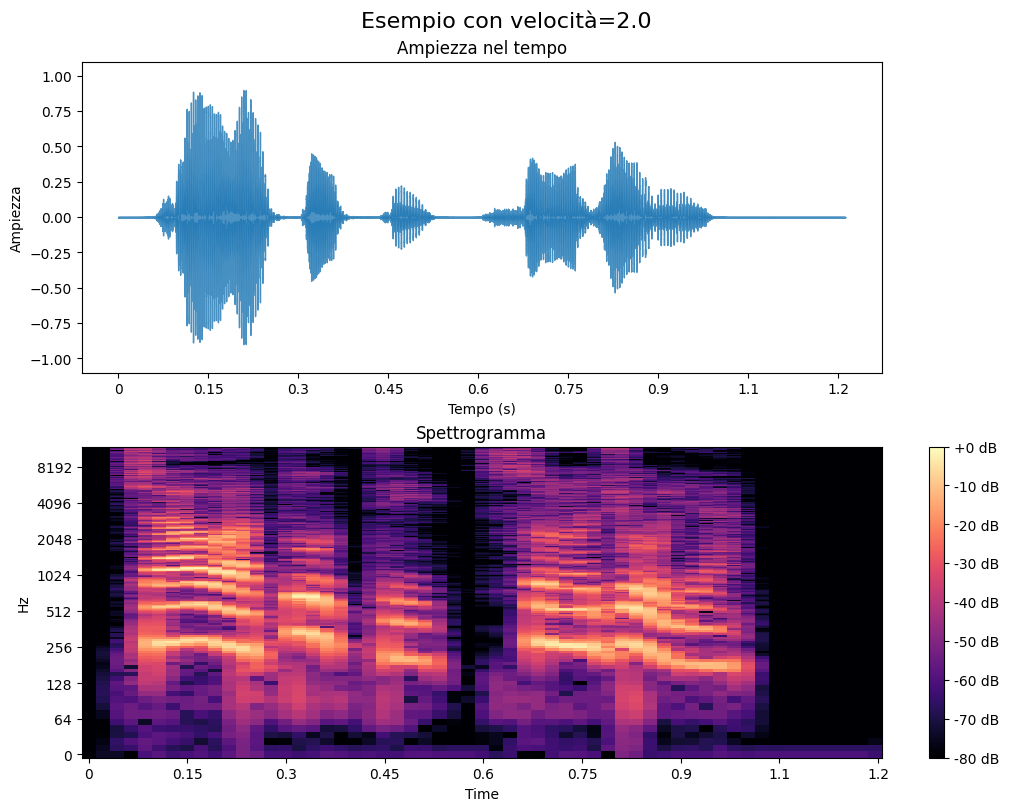

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y = change_speed(y_base, 2.0)

    y = y / (np.max(np.abs(y)) + 0.001) * 0.9

    display(Audio( y, rate=sr_base))
    plot_analysis(y, sr_base, f"Esempio con velocità=2.0")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

## Pitch
Il secondo effetto è il pitch shifting, che a differenza del primo, disaccoppia il tempo dalla frequenza.

Qui l'obiettivo è cambiare l'intonazione senza alterare la velocità di riproduzione. L'algoritmo scompone il segnale in piccole finestre temporali usando la STFT (short-time fourier transform), trasla le frequenze nel dominio spettrale e poi ricostruisce il segnale.

Librosa utilizza un algoritmo basato sul Phase Vocoder.
Il processo può essere spiegato in tre stadi:
- Trasformiamo il segnale dal dominio del tempo al dominio della frequenza usando la STFT. Il segnale viene tagliato in piccolissime finestre sovrapposte.
- Per alzare il pitch di $n$ semitoni senza cambiare la velocità, l'algoritmo fa 'time-stretch' nel segnale originale per renderlo più lungo, usando il Phase Vocoder per mantenere il pitch originale.
- Infine, dopo aver allungato il file al doppio della durata, lo riproduce a velocità doppia. Il risultato avrà quindi la  durata originale, ma pitch raddoppiato.

fonti: https://babyaud.io/blog/phase-vocoder, https://librosa.org/doc/0.11.0/generated/librosa.effects.pitch_shift.html#librosa.effects.pitch_shift

In [ ]:
#modifica pitch
def change_pitch(y, sr, semitones=0):
    if semitones != 0:
        y = librosa.effects.pitch_shift(y=y, sr=sr, n_steps=semitones)
    return y

###Analisi dei grafici

Nel grafico dell'ampiezza nel mempo, possiamo notare che la durata totale del file rimane invariata. Questo dimostra l'indipendenza tra durata temporale e contenuto frequenziale ottenuta grazie all'algoritmo.

Nello spettrogramma, le frequenze si spostano verso l'alto, in quanto diventano più acute.

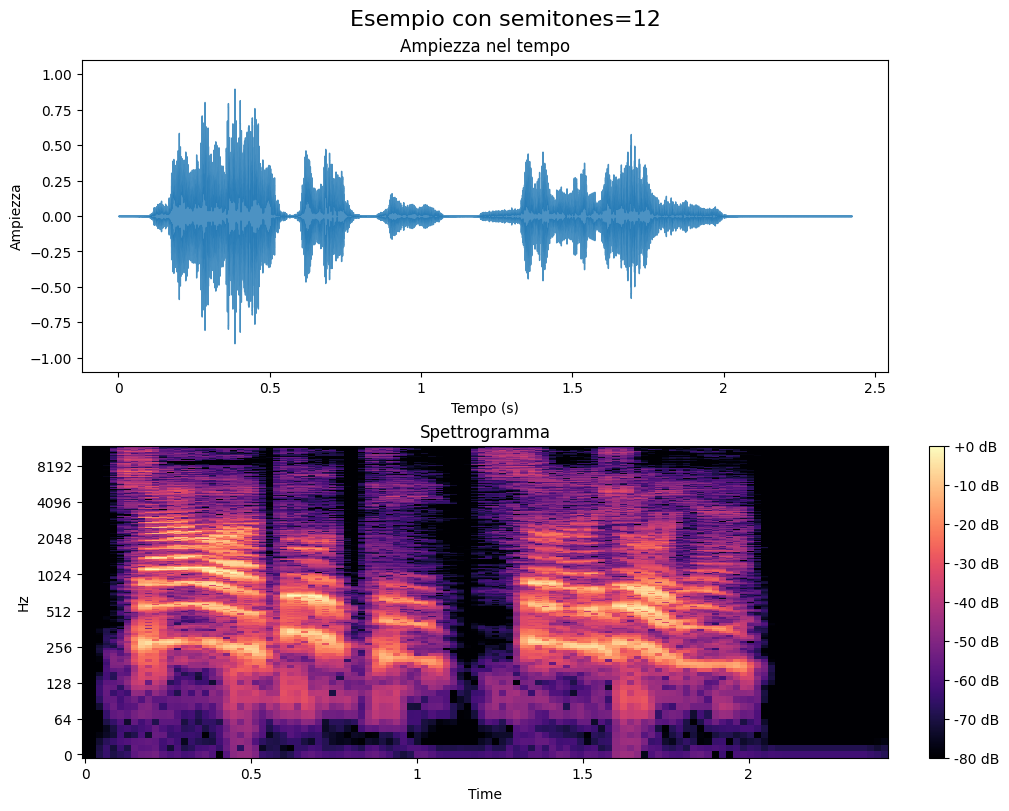

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y = change_pitch(y_base, sr_base, semitones=12)

    y = y / (np.max(np.abs(y)) + 0.001) * 0.9

    display(Audio( y, rate=sr_base))
    plot_analysis(y, sr_base, f"Esempio con semitones=12")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

## Filtro Qualità (bitcrushing)
Infine, ho implementato un effetto di bitcrushing, che agisce sulla risoluzione in ampiezza del segnale, ovvero la bit depth.
In digitale, l'onda sonora non è continua ma discreta. L'asse verticale, l'ampiezza, è diviso in un numero finito di livelli, determinato dalla formula $2^N$.

A 16 bit abbiamo 65.536 (ossia $2^{16}$) livelli: riducendo i bit a 4, riduciamo i livelli disponibili a 16. Il codice forza ogni campione ad adattarsi al "gradino" più vicino. La differenza tra il valore originale e quello approssimato genera quello che chiamiamo 'rumore di quantizzazione'.

fonte: https://unison.audio/bitcrushing-and-downsampling/

In [ ]:
#modifica qualità (bit)
def bitcrush(y, bits=16):
    q = 2 ** (bits - 1)
    y = np.round(y * q) / q
    return y

###Analisi dei grafici

Nel grafico dell'ampiezza del tempo, vediamo una forma a gradini. Visto che, se riduco a 4 bit, ci sono solo 16 livelli di volume disponibili, l'onda non può scendere gradualmente verso lo zero: salta bruscamente da un livello all'altro. Questo crea visivamente una forma a blocchi o scalini.

Nello spettrogramma, il cambiamento più evidente è lo sfondo, che diventa viola per il rumore di quantizzazione, ma solo nei punti in cui il segnale non è a zero. Altrimenti, nelle pause, lo sfondo diventa completamente nero.

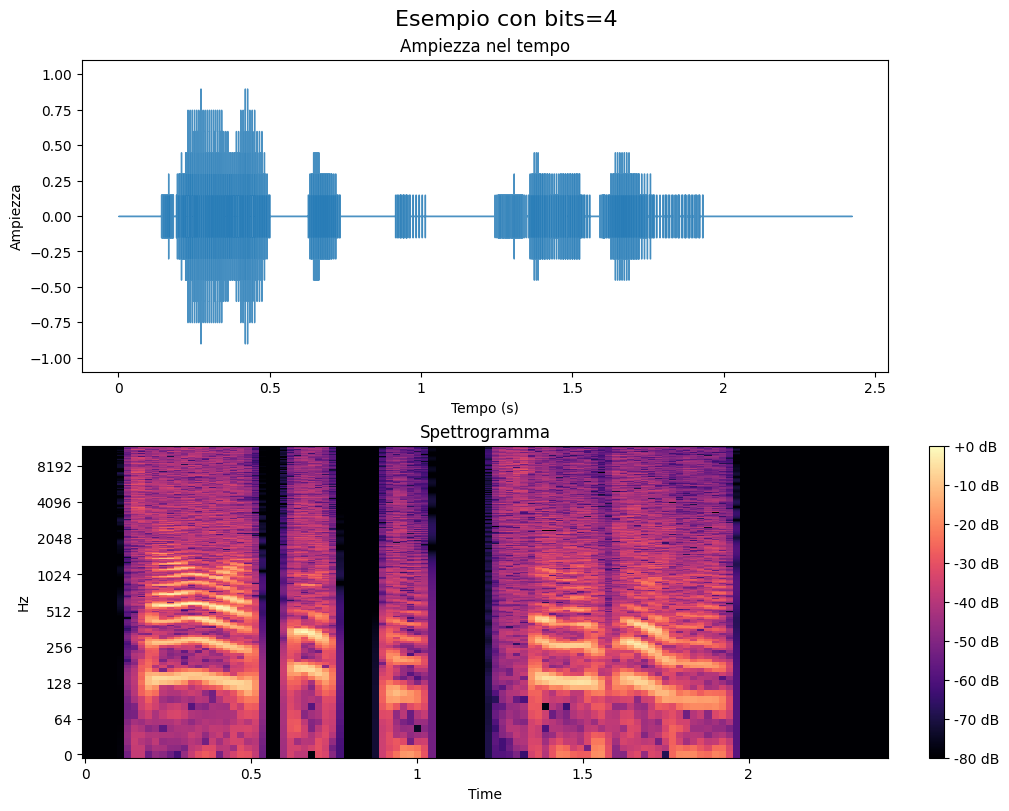

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y = bitcrush(y_base, bits=4)

    y = y / (np.max(np.abs(y)) + 0.001) * 0.9

    display(Audio( y, rate=sr_base))
    plot_analysis(y, sr_base, f"Esempio con bits=4")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

#Editor

Questo è l'editor che permette di modificare l'audio tramite sliders.

Utilizzandolo, si possono vedere tutte le situazioni possibili e come infuiscono sull'audio e sui grafici.

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    sl_pitch = widgets.IntSlider(min=-12, max=12, step=1, value=0, description="Pitch:")
    sl_speed = widgets.FloatSlider(min=0.5, max=3, step=0.1, value=1, description="Velocità:")
    sl_bits = widgets.IntSlider(min=4, max=16, step=1, value=16, description="Qualità (Bit):")

    out = widgets.Output()

    def update_audio(speed, pitch, bits):
        y = np.copy(y_base)

        y = change_speed(y, speed)
        y = change_pitch(y, sr_base, pitch)
        y = bitcrush(y, bits)

        y = y / (np.max(np.abs(y)) + 0.001) * 0.9

        display(Audio(y, rate=sr_base))
        plot_analysis(y, sr_base, f"Pitch: {pitch} / Speed: {speed} / Bits: {bits}")

    ui = widgets.VBox([
        widgets.HBox([sl_speed, sl_pitch, sl_bits])
    ])

    out = widgets.interactive_output(update_audio, {
        'speed': sl_speed,
        'pitch': sl_pitch,
        'bits': sl_bits
    })

    display(ui, out)

else:
    print("Impossibile generare l'audio iniziale.")

Output()

In questa parte del notebook, ho emulato alcuni effetti che si possono trovare nella vita di tutti i giorni o nei videogiochi.

#Animalese: il linguaggio di *Animal Crossing*

In [ ]:
# simula voce dei villager di Animal Crossing
def animalese(y, sr):
    y = change_speed(y, 2.4)

    seg_len = int(0.055 * sr)  # segmentazione in 'sillabe'
    gap_len = int(0.005 * sr)  # pausa tra una sillaba e l'altra

    new_y = []

    window = np.hanning(seg_len)

    for i in range(0, len(y), seg_len):
        chunk = y[i:i+seg_len]  # segmento corrente
        if len(chunk) == seg_len:
            chunk = chunk * window
            new_y.extend(chunk)
            new_y.extend(np.zeros(gap_len))
        elif len(chunk) > 0: # ultimo chunk < 0.055
            temp_win = np.hanning(len(chunk)) # finestra di hanning 'personalizzata'
            new_y.extend(chunk * temp_win)

    return np.array(new_y)

Nella serie di videogiochi *Animal Crossing* sei l'unico umano in un mondo con personaggi animali. Questi animali, con cui puoi interagire, hanno una parlata, che è stata poi nominata 'Animalese', distinta da una velocità elevata, pitch alto e divisione sillabica.

Il gioco non manipola una registrazione vocale intera come fa il mio script: legge il testo del dialogo carattere per carattere, e ogni singola lettera è associata a un brevissimo file audio pre-registrato. Il gioco attacca insieme questi suoni in tempo reale, creando la parola.

Nel gioco, ogni personalità o personaggio ha una voce diversa, che viene cambiata modificando semplicemente il pitch o la velocità, generando un'infinita varietà di voci partendo dalla stessa sorgente.

###Come ho creato l'effetto?

La prima operazione che vediamo nel codice è **change_speed(y, 2.4)**. Il segnale audio originale viene accelerato di 2.4 volte. Nel dominio digitale, se aumentiamo la velocità di riproduzione senza correggere il pitch, otteniamo automaticamente un innalzamento della frequenza. Questo crea quella voce acuta e rapida tipica dei personaggi del gioco.

Per creare l'effetto delle sillabe, nel codice definisco una **seg_len**, ossia la lunghezza del segmento, di circa 55 millisecondi e un **gap_len**, ossia una pausa, di 5 millisecondi.

All'interno del ciclo for, applico una finestra di Hanning (**np.hanning**) a ogni frammento. La finestra di Hanning smussa l'inizio e la fine di ogni segmento, portandoli gradualmente a zero: è come se fosse un fade-in e un fade-out applicato ad ogni segmento. La uso perchè quando taglio l'audio in segmenti per simulare le sillabe, non sempre la parte finale del segmento sarà 'in silenzio'. Se non la usassi, tra ogni sillaba si creerebbe una discontinuità, un disturbo fastidioso.

La finestra di Hanning è definita dalla seguente formula: $$w(n) = 0.5 \left( 1 - \cos \left( \frac{2\pi n}{N - 1} \right) \right)$$

$n$ è l'indice del campione corrente, con $0 \le n \le N-1$.

$N$ è la lunghezza totale della finestra (quindi il numero di campioni del segmento).

Il termine $\cos(\frac{2\pi n}{N-1})$ genera una classica onda cosinusoidale che compie un ciclo completo all'interno della lunghezza $N$. Normalmente, il coseno oscilla tra $-1$ e $1$. L'operazione $1 - \cos(\frac{2\pi n}{N-1})$ inverte l'onda e la solleva. Quando il coseno è $1$ (agli estremi), il risultato è $1 - 1 = 0$. Quando il coseno è $-1$ (al centro), il risultato è $1 - (-1) = 2$. Infine, il fattore $0.5$ dimezza l'ampiezza.

Il valore massimo, al centro della finestra, diventa $1$. Il valore minimo, agli estremi, diventa $0$.
Il risultato è una curva a forma di campana perfetta che parte da zero, sale dolcemente fino a uno e ritorna a zero.

fonte: https://wraycastle.com/it/blogs/knowledge-base/hanning-window

Infine, l'array new_y viene costruito alternando questi segmenti smussati a brevi pause di silenzio (np.zeros(gap_len)). L'elif gestisce l'ultimo segmento dell'audio, che potrebbe quindi essere più corto di 55 millisecondi, creando una finestra di hanning della sua lunghezza.

###Analisi dei grafici

Nel grafico dell'ampiezza nel tempo, si nota che la forma dell'onda non è continua. Questa è la rappresentazione visiva diretta dell'applicazione della Finestra di Hanning e dell'inserimento dei gap, delle pause.

Nello spettrogramma, le linee orizzontali luminose ci mostrano che, nonostante la pesante manipolazione, la struttura armonica della voce è preservata, seppur traslata verso l'alto in frequenza.

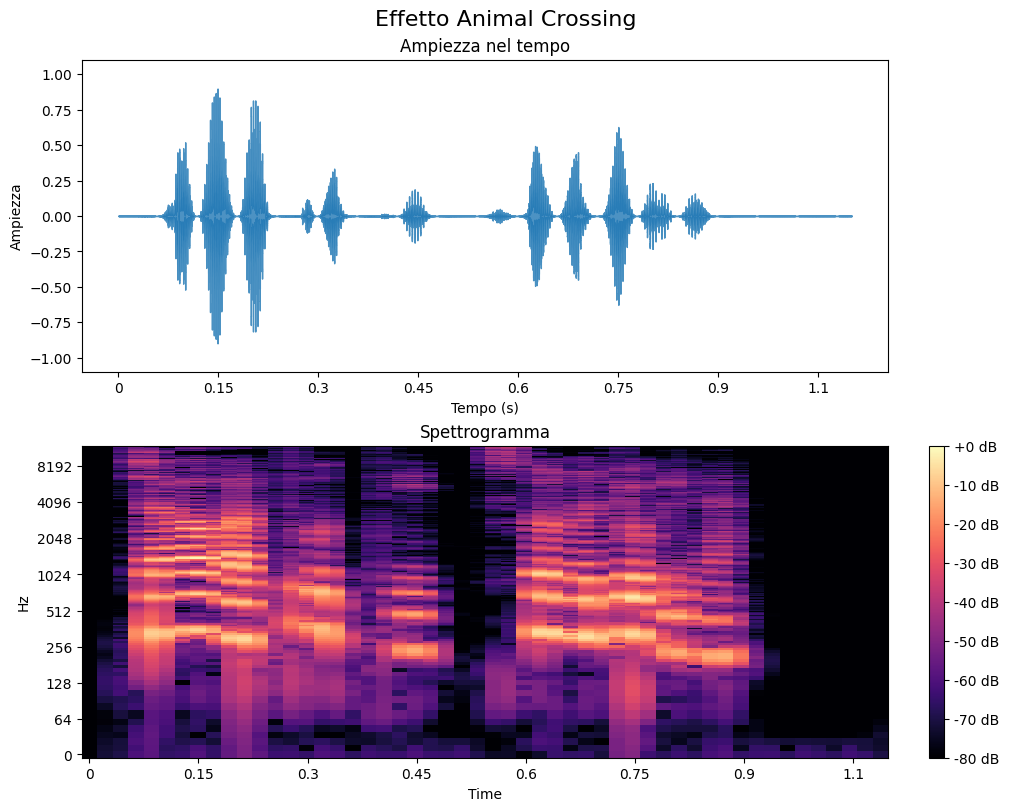

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y_animalcrossing = animalese(y_base, sr_base)

    y_animalcrossing = y_animalcrossing / (np.max(np.abs(y_animalcrossing)) + 0.001) * 0.9

    display(Audio( y_animalcrossing, rate=sr_base))
    plot_analysis(y_animalcrossing, sr_base, f"Effetto Animal Crossing")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

#Radio: effetto ricetrasmettitore

In [ ]:
def radio(y, sr, noise_level=0.005):
    def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs  # fs/2
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return b, a

    def bandpass_filter(data, lowcut, highcut, fs, order=5):
        b, a = butter_bandpass(lowcut, highcut, fs, order=order)
        y = lfilter(b, a, data)
        return y

    y_filtered = bandpass_filter(y, 300, 3400, sr, order=6) # applico passabanda

    noise = np.random.normal(0, 1, len(y_filtered)) # rumore bianco
    y_noisy = y_filtered + (noise * noise_level)

    y_out = np.tanh(y_noisy * 2) # distorsione

    return y_out

Questo algoritmo vuole replicare l'effetto delle radio ricetrasmittenti, dei walkie-talkie.

Uso un filtro Butterworth, configurato come Passa-Banda tra i 300 Hz e i 3400 Hz. Questo perchè, in telefonia, la banda di frequenze per la voce è compresa approssimativamente tra 300 Hz e 3400 Hz.

fonte = https://it.wikipedia.org/wiki/Banda_fonica

Uso un filtro Butterworth perchè ha una finestra tendente al rettangolare che taglia via i bassi (sotto i 300Hz) e gli acuti (sopra i 3400Hz) in modo deciso, netto. Il filtro Butterworth è noto per avere una risposta in frequenza massimamente piatta nella banda passante, ideale per isolare segnali con determinate frequenze e rimuovere quelle indesiderate, senza ripple (ondulazioni).

Il filtro gaussiano ha, per definizione, la forma di una campana curva. Se lo usassi come passa-banda centrato sulla voce, si sentirebbero bene solo le frequenze centrali (1000Hz), mentre le frequenze più basse o più alte verrebbero attenuate pesantemente.
Ha una discesa molto dolce e graduale, che non riesce a creare quel taglio netto creato invece dal filtro Butterworth.

###Come ho creato l'effetto?

Quando creo il filtro Butterworth, inizio calcolando la frequenza di Nyquist: secondo il teorema del campionamento, l’ampiezza del periodo nelle frequenze è duale all’ampiezza del periodo nel tempo. Quindi, la massima frequenza gestibile è sempre la metà della frequenza di campionamento ($fs / 2$).

Devo poi dividere le frequenze che voglio usare come limite con quest'ultima: le funzioni di filtro digitale non usano gli Hz, ma vogliono un numero tra 0.0 e 1.0, dove 1.0 è la frequenza di Nyquist. In questo modo converto i limiti 300Hz e 3400Hz in questa scala che va da 0 a 1.

La funzione **butter**, della libreria scipy.signal, serve a progettare il filtro Butterworth. La funzione restituisce i coefficienti del numeratore (b) e del denominatore (a) della funzione di trasferimento del filtro, che vengono usati per applicare il filtro al segnale.
L'ordine determina la ripidità del taglio del filtro: un ordine maggiore rende il taglio più ripido.

fonte: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html

I sistemi analogici soffrono di interferenze che nel codice simulo aggiungendo Rumore Bianco Gaussiano (**np.random.normal**). Questo crea un array di numeri casuali della stessa lunghezza del segnale audio.

Infine, aggiungo una leggera distorsione. Per farlo, uso **np.tanh**. La funzione tangente iperbolica mappa qualsiasi input in un intervallo compreso tra -1 e +1.

La formula è:$$\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$$

L'effetto sul segnale audio si divide in due fasi, dipendenti dall'ampiezza dell'input:
- quando l'input $x$ è vicino allo zero, la funzione si comporta quasi linearmente: $\tanh(x) \approx x$. I suoni deboli passano quasi inalterati.
- man mano che l'input $x$ cresce, la curva smette di salire linearmente e inizia a piegarsi per avvicinarsi a $1$ (o $-1$ per valori negativi) senza mai superarlo.

fonti: https://ccrma.stanford.edu/~jos/pasp/Soft_Clipping.html, https://numpy.org/doc/stable/reference/generated/numpy.tanh.html

Moltiplicare il segnale per 2 prima di applicare la funzione (**y_noisy * 2**) equivale ad alzare il gain, il guadagno, in ingresso, forzando volontariamente il segnale verso la zona non-lineare della curva. Questo processo fa in modo che i suoni forti vengono limitati, mentre i suoni deboli vengono amplificati. Il risultato è un suono più denso, "sporco".

###Analisi dei grafici

Nel grafico dell'ampiezza nel tempo, si distinguono chiaramente dei pacchetti di segnale, che corrispondono alle parole pronunciate. I picchi sono stati compressi dinamicamente con tanh, riducendo la gamma dinamica e rendendo il suono più aggressivo e presente, tipico di una trasmissione radiofonica. Al contrario dei grafici che abbiamo visto in precedenza, questo non presenta mai un silenzio, ossia una linea retta.

Nello spettrogramma possiamo vedere l'effetto del filtro butter_bandpass: le zone sotto circa 300 Hz e quelle sopra circa 3400 Hz sono quasi completamente scure, e tutta l'energia è concentrata nella fascia centrale. Si può inoltre notare chiaramente il rumore bianco, che rende lo sfondo mai del tutto scuro.

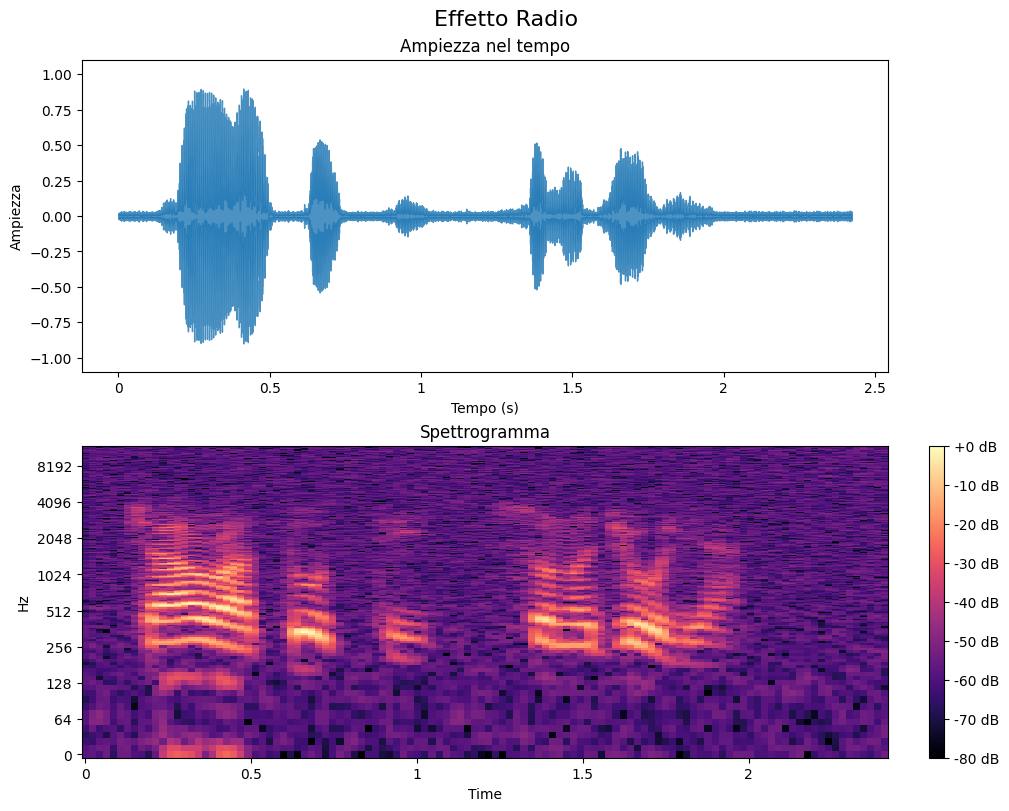

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y_radio = radio(y_base, sr_base)

    y_radio = y_radio / (np.max(np.abs(y_radio)) + 0.001) * 0.9

    display(Audio( y_radio, rate=sr_base))
    plot_analysis(y_radio, sr_base, f"Effetto Radio")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

#Underwater: effetto sott'acqua

In [ ]:
def underwater(y, sr):
    def butter_lowpass(cutoff, fs, order=6):
        nyq = 0.5 * fs
        normal_cutoff = cutoff / nyq
        b, a = butter(order, normal_cutoff, btype='low', analog=False)
        return b, a

    def lowpass_filter(data, cutoff, fs, order=6):
        b, a = butter_lowpass(cutoff, fs, order=order)
        y = lfilter(b, a, data)
        return y

    y_out = lowpass_filter(y, 600, sr, order=6) # Taglia tutto sopra i 600Hz
    return y_out

Questo effetto vuole ricreare la percezione del suono sott'acqua. I suoni appaiano 'ovattati' e privi di dettagli quando siamo immersi. Fisicamente, questo accade perché le alte frequenze vengono assorbite molto più rapidamente delle basse frequenze nell'acqua. Per replicare questo effetto digitalmente, utilizzo il filtro passa-basso.

Per simulare l'effetto underwater, l'obiettivo non è semplicemente abbassare il volume delle alte frequenze, ma eliminarle drasticamente mantenendo però inalterato il volume delle basse frequenze. Il taglio netto del filtro Butterworth è essenziale, visto che sott'acqua l'assorbimento delle alte frequenze è drastico, non graduale. Per questo motivo non ho usato il filtro Gaussiano: ha una discesa in frequenza troppo morbida, per seguire la sua curva a campana. Questo farebbe si che, se impostassi il taglio a 600Hz, l'attenuazione della frequenza partirebbe molto prima, già nei 300Hz circa.

### Come ho creato l'effetto?

Come nel filtro Radio, inizio calcolando la frequenza di Nyquist. Poi converto il cutoff, ossia il valore della frequenza da cui voglio tagliare, per la scala di Nyquist (0.0 - 1.0).

**Butter** chiama la funzione di libreria per generare il filtro Butterworth; b e a sono i coefficienti dell'equazione differenziale che definisce il filtro. Il **btype='low'** specifica che vogliamo un filtro passa-basso.

Infine chiamo la funzione **lowpass_filter**, impostando la frequenza di taglio come 600Hz, per eliminare i dettagli e le armoniche della voce, lasciando solo le frequenze fondamentali basse: questo crea l'effetto ovattato.

###Analisi dei grafici

Nel grafico dell'ampiezza nel tempo notiamo che ci sono segmenti di silenzio e segmenti di parlato ben definiti. Non si notano grandi cambiamenti: questo perchè i cambiamenti più importanti avvengono sulle frequenze.

Lo spettrogramma mostra che le alte frequenze sono completamente nere. Le frequenze sono presenti solo sotto a 600Hz, e da lì scemano fino a scomparire.



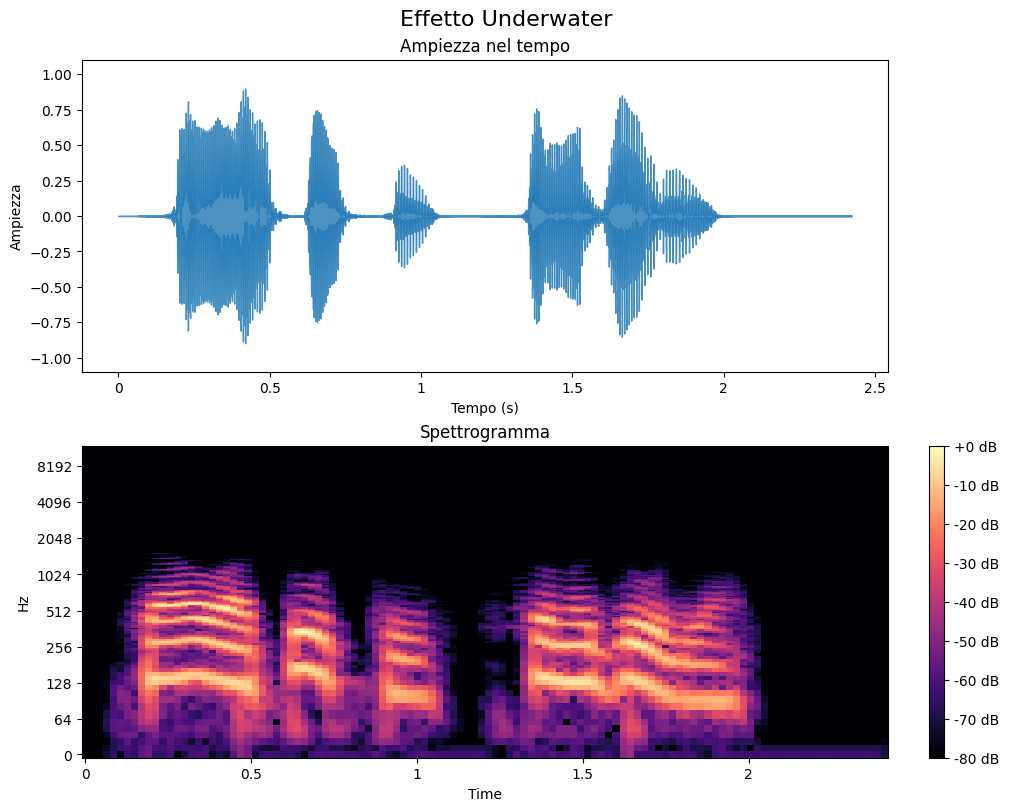

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y_underwater = underwater(y_base, sr_base)

    y_underwater = y_underwater / (np.max(np.abs(y_underwater)) + 0.001) * 0.9

    display(Audio( y_underwater, rate=sr_base))
    plot_analysis(y_underwater, sr_base, f"Effetto Underwater")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

## Conclusioni

###Cosa ho imparato?

Durante lo sviluppo di questo progetto, ho approfondito come l'elaborazione dei segnali possano alterare radicalmente la percezione di una voce, partendo da semplici manipolazioni fino a effetti più complessi.

Ho compreso la differenza tra il semplice ricampionamento (resampling), che vincola velocità e intonazione, e algoritmi più complessi come il Phase Vocoder, che permettono di disaccoppiare queste due grandezze.

Analizzando l'effetto bitcrushing, ho visualizzato concretamente il concetto di bit depth, osservando come la riduzione dei livelli di ampiezza generi rumore e una forma d'onda "a gradini".

Ho imparato a utilizzare la libreria scipy.signal per progettare filtri. Ho capito l'importanza della frequenza di Nyquist per convertire le frequenze reali in valori normalizzati utilizzabili dagli algoritmi. Inoltre, ho appreso come i filtri Butterworth siano essenziali per isolare bande di frequenza specifiche.

Ho visto come funzioni matematiche pure possano simulare fenomeni reali: la tangente iperbolica per simulare la distorsione analogica nel filtro Radio, e l'eliminazione delle alte frequenze per simulare l'assorbimento acustico dell'acqua.

###Cosa non ha funzionato?

Durante la sperimentazione, ho dovuto scartare alcuni approcci iniziali che non restituivano i risultati sperati.

Nel filtro "Animal Crossing", non ho potuto usare dei file audio per ogni lettera dell'alfabeto come fa il gioco: ho quindi deciso di dividere l'audio creato in segmenti per simulare la divisione delle lettere. Ho anche notato che tagliare semplicemente l'audio in segmenti creava discontinuità udibili tra una "sillaba" e l'altra. Ho dovuto quindi implementare la finestra di hanning per smussare l'inizio e la fine di ogni frammento, eliminando i disturbi di transizione.

Per gli effetti "Radio" e "Underwater", ho compreso che un filtro con andamento gaussiano, troppo graduale, non funzionava efficacemente. Nel caso della radio, non tagliava nettamente i bassi e gli acuti come un vero dispositivo elettronico; nel caso dell'acqua, la discesa troppo morbida avrebbe attenuato le frequenze medie troppo presto, invece di preservarle fino al taglio netto dei 600Hz necessario per l'effetto ovattato.